In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv(r"sampled_data_1.csv")
df_sample = df.sort_values(by='Start_Time', ascending=False).head(10000)

In [ ]:
# some preprocessing on this data 
print("first 5 row",df_sample.head())
print("************************************")

print("last 5 rows",df_sample.tail())
print("************************************")

print(df_sample.info())
print("************************************")

print("statistical properties: ",df_sample.describe())
print("************************************")

In [ ]:
#  EDA (some cleaning for data)
print("size of data: ", df_sample.shape)
print("************************************")
print("type of data: ", df_sample.dtypes)
print("************************************")
print(df_sample.isnull().sum())
print("************************************")
print(df.duplicated().sum())

In [ ]:
# convert 'Start_Time' to datetime
df_sample['Start_Time'] = pd.to_datetime(df_sample['Start_Time'], errors='coerce')
df_sample['End_Time'] = pd.to_datetime(df_sample['End_Time'], errors='coerce')

df_sample['Duration'] = (df_sample['End_Time'] - df_sample['Start_Time']).dt.total_seconds()

df_sample['Day_of_Week'] = df_sample['Start_Time'].dt.day_name()
df_sample['Month'] = df_sample['Start_Time'].dt.month
df_sample['Year'] = df_sample['Start_Time'].dt.year

In [ ]:
# drop columns End-lat and End-lon
df_sample.drop(columns=['End_Lat', 'End_Lng', 'Precipitation(in)'], inplace=True)

In [ ]:
columns_to_impute = [
    'Distance(mi)', 
    'Temperature(F)', 
    'Wind_Chill(F)', 
    'Humidity(%)', 
    'Pressure(in)', 
    'Visibility(mi)'
]

existing_columns = [col for col in columns_to_impute if col in df_sample.columns]
column_means = df_sample[existing_columns].mean()
df_sample[existing_columns] = df_sample[existing_columns].fillna(column_means)

df_sample['Distance(mi)'].value_counts()

In [ ]:
# to check cleaning data 
df_sample.isnull().sum()

In [ ]:
df_sample['Wind_Direction'].value_counts()

In [ ]:
# Step 1: Calculate the median excluding zeros
non_zero_median = df_sample.loc[df_sample['Wind_Speed(mph)'] != 0, 'Wind_Speed(mph)'].median()

# Step 2: Replace zeros with that median
df_sample.loc[df_sample['Wind_Speed(mph)'] == 0, 'Wind_Speed(mph)'] = non_zero_median

df_sample['Wind_Speed(mph)'].value_counts()

In [ ]:
df_sample.groupby('Wind_Direction')['Wind_Speed(mph)'].value_counts()

In [ ]:
# feature engineering
# #1-   Time-Based Features
# Define a function to classify hours into time-of-day categories
def time_of_day(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

# Feature engineering
if 'Start_Time' in df_sample.columns:
    if 'hour' not in df_sample.columns:
        df_sample['hour'] = pd.to_datetime(df_sample['Start_Time']).dt.hour
    if 'day_of_week' not in df_sample.columns:
        df_sample['day_of_week'] = pd.to_datetime(df_sample['Start_Time']).dt.dayofweek

    # Apply transformations
    df_sample['time_of_day'] = df_sample['hour'].apply(time_of_day)
    df_sample['is_weekend'] = df_sample['day_of_week'].isin([5, 6]).astype(int)
else:
    print("Error: 'Start_Time' column not found in DataFrame")


In [ ]:
# 2. Weather Condition Features
# Simplify weather conditions into broader categories
def categorize_weather(condition):
    if pd.isna(condition):
        return 'Unknown'
    condition = condition.lower()
    if 'rain' in condition or 'shower' in condition:
        return 'Rainy'
    elif 'snow' in condition or 'ice' in condition or 'sleet' in condition:
        return 'Snowy'
    elif 'fog' in condition or 'haze' in condition or 'mist' in condition:
        return 'Foggy'
    elif 'cloud' in condition:
        return 'Cloudy'
    elif 'clear' in condition or 'fair' in condition:
        return 'Clear'
    elif 'wind' in condition:
        return 'Windy'
    else:
        return 'Other'
    
df_sample['weather_category'] = df_sample['Weather_Condition'].apply(categorize_weather)

In [ ]:
# 3. Location-Based Features
# Calculate distance between start and end points (approximate)
df_sample['distance_km'] = df_sample['Distance(mi)'] * 1.60934

# Create region feature based on state
def get_region(state):
    northeast = ['CT', 'ME', 'MA', 'NH', 'RI', 'VT', 'NJ', 'NY', 'PA']
    midwest = ['IL', 'IN', 'MI', 'OH', 'WI', 'IA', 'KS', 'MN', 'MO', 'NE', 'ND', 'SD']
    south = ['DE', 'FL', 'GA', 'MD', 'NC', 'SC', 'VA', 'DC', 'WV', 'AL', 'KY', 'MS', 'TN', 'AR', 'LA', 'OK', 'TX']
    west = ['AZ', 'CO', 'ID', 'MT', 'NV', 'NM', 'UT', 'WY', 'AK', 'CA', 'HI', 'OR', 'WA']
    
    if state in northeast:
        return 'Northeast'
    elif state in midwest:
        return 'Midwest'
    elif state in south:
        return 'South'
    elif state in west:
        return 'West'
    else:
        return 'Unknown'
    
df_sample['region'] = df_sample['State'].apply(get_region)

In [ ]:
# 4. Road Condition Features
# Create binary flags for road features
road_features = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 
                 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 
                 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop']

for feature in road_features:
    df_sample[f'has_{feature.lower()}'] = df_sample[feature].astype(int)

# Count of road features at accident location
df_sample['road_feature_count'] = df_sample[road_features].sum(axis=1)

In [ ]:
# 5. Severity Features
# Create severity categories
def categorize_severity(severity):
    if severity == 1:
        return 'Low'
    elif severity == 2:
        return 'Medium'
    elif severity == 3:
        return 'High'
    else:
        return 'Very High'
    
df_sample['severity_category'] = df_sample['Severity'].apply(categorize_severity)

# Interaction between weather and severity
df_sample['weather_severity'] = df_sample['weather_category'] + '_' + df_sample['severity_category']

In [ ]:
# 6. Temporal Aggregation Features
# Calculate accidents per hour (for normalization)
accidents_per_hour = df_sample.groupby('hour').size().reset_index(name='accidents_per_hour')
df_sample = df_sample.merge(accidents_per_hour, on='hour', how='left')

# Calculate severity by hour
severity_by_hour = df_sample.groupby('hour')['Severity'].mean().reset_index(name='avg_severity_by_hour')
df_sample = df_sample.merge(severity_by_hour, on='hour', how='left')

In [ ]:
# 7-visualizing for feature engineering 
import matplotlib.pyplot as plt
import seaborn as sns
# Plot accidents by time of day
plt.figure(figsize=(12, 6))
sns.countplot(data=df_sample, x='time_of_day', order=['Morning', 'Afternoon', 'Evening', 'Night'], 
              palette='viridis')
plt.title('Accidents by Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Number of Accidents')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Plot accidents by weather category
plt.figure(figsize=(12, 6))
sns.countplot(data=df_sample, x='weather_category', 
              order=df_sample['weather_category'].value_counts().index,
              palette='viridis')
plt.title('Accidents by Weather Category')
plt.xlabel('Weather Category')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Plot severity by region
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_sample, x='region', y='Severity', palette='viridis')
plt.title('Accident Severity by Region')
plt.xlabel('Region')
plt.ylabel('Severity Level')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [70]:
# 8. Feature Selection
selected_features = [
    'hour', 'day_of_week', 'month', 'time_of_day', 'is_weekend',
    'weather_category', 'region', 'distance_km', 'road_feature_count',
    'severity_category', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)',
    'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 
    'has_amenity', 'has_bump', 'has_crossing', 'has_give_way', 
    'has_junction', 'has_no_exit', 'has_railway', 'has_roundabout',
    'has_station', 'has_stop', 'has_traffic_calming', 
    'has_traffic_signal', 'has_turning_loop',
    'accidents_per_hour', 'avg_severity_by_hour'
]

# Target variable
target = 'Severity'

Benefits of This Feature Engineering
Improved Predictive Power: The new features capture more nuanced patterns in accident data

Enhanced Interpretability: Categorical groupings make patterns easier to understand

Better Normalization: Features like accidents-per-hour account for baseline traffic patterns

Interaction Effects: Combined features (like weather-severity) capture complex relationships

Reduced Dime


# The Most Hours 12 -> 6 pm
# The Most Hour -> 3 pm

c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


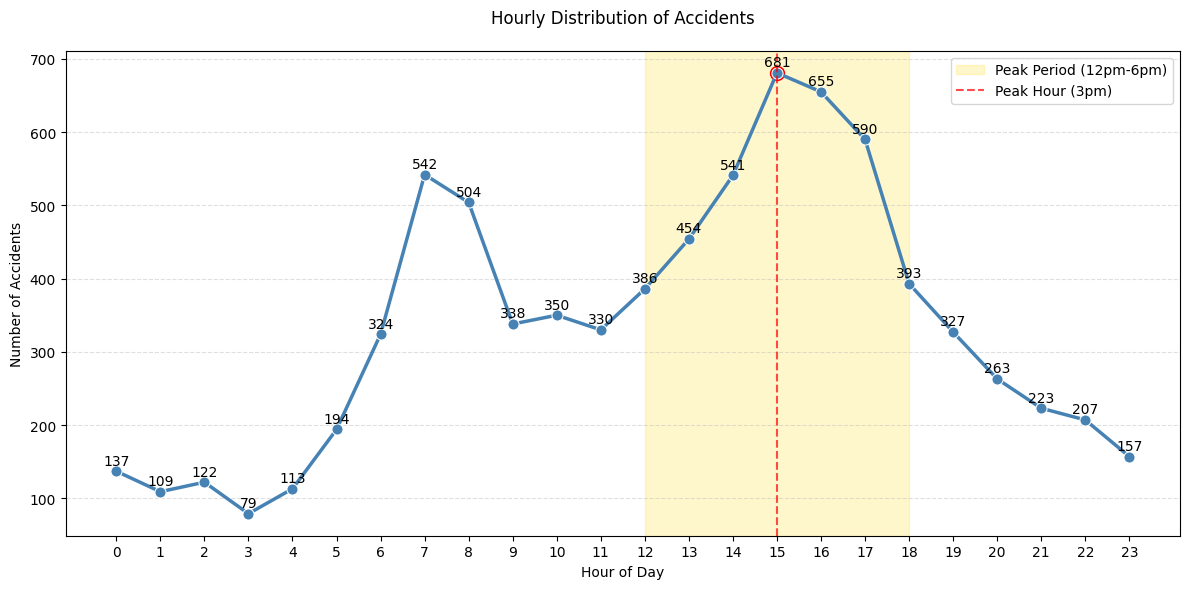

In [71]:
# line plot
import matplotlib.pyplot as plt
import seaborn as sns

# Extract hour from Start_Time if not already done
df_sample['hour'] = df_sample['Start_Time'].dt.hour

# Create the line plot
plt.figure(figsize=(12, 6))

# Calculate hourly counts
hourly_counts = df_sample['hour'].value_counts().sort_index()

# Create line plot with markers
sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, 
             marker='o', color='steelblue', linewidth=2.5, markersize=8)

# Highlight peak hours (12pm-6pm)
plt.axvspan(12, 18, color='gold', alpha=0.2, label='Peak Period (12pm-6pm)')

# Highlight the peak hour (3pm)
plt.axvline(x=15, color='red', linestyle='--', alpha=0.7, label='Peak Hour (3pm)')
plt.scatter(x=15, y=hourly_counts[15], color='red', s=100)

# Customize the plot
plt.title("Hourly Distribution of Accidents", pad=20)
plt.xlabel("Hour of Day")
plt.ylabel("Number of Accidents")
plt.xticks(range(24))
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Add value labels at each point
for hour, count in hourly_counts.items():
    plt.text(hour, count+5, str(count), ha='center', va='bottom')

plt.tight_layout()
plt.show()

c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: us

<Figure size 1400x1000 with 0 Axes>

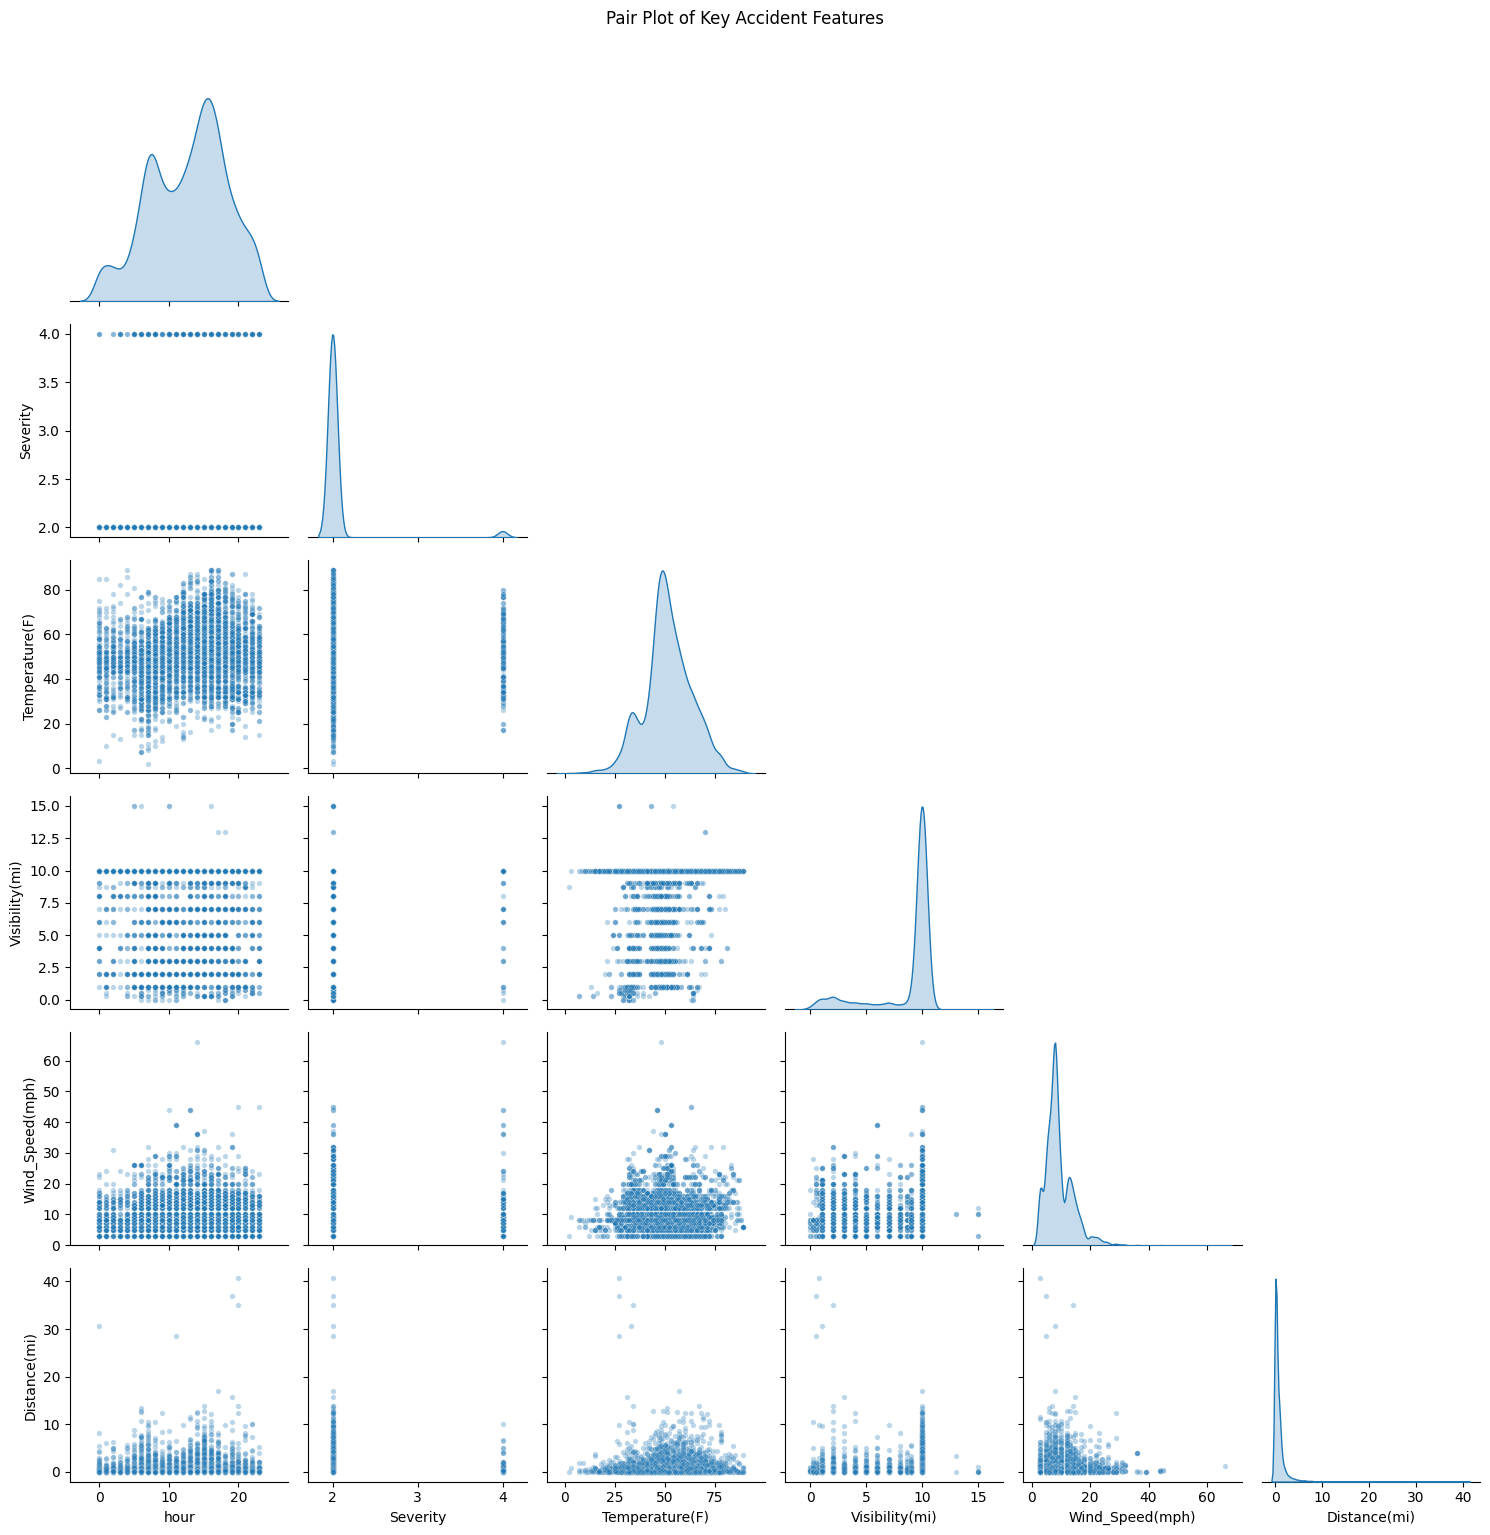

In [72]:
# pair plot
# Select key numerical features for pair plot
pair_plot_features = ['hour', 'Severity', 'Temperature(F)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Distance(mi)']

plt.figure(figsize=(14, 10))
sns.pairplot(df_sample[pair_plot_features].dropna(), 
             diag_kind='kde',  # Use kernel density for diagonals
             plot_kws={'alpha': 0.3, 's': 15},  # Scatterplot settings
             corner=True)  # Show only lower triangle
plt.suptitle('Pair Plot of Key Accident Features', y=1.02)
plt.tight_layout()
plt.show()

c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


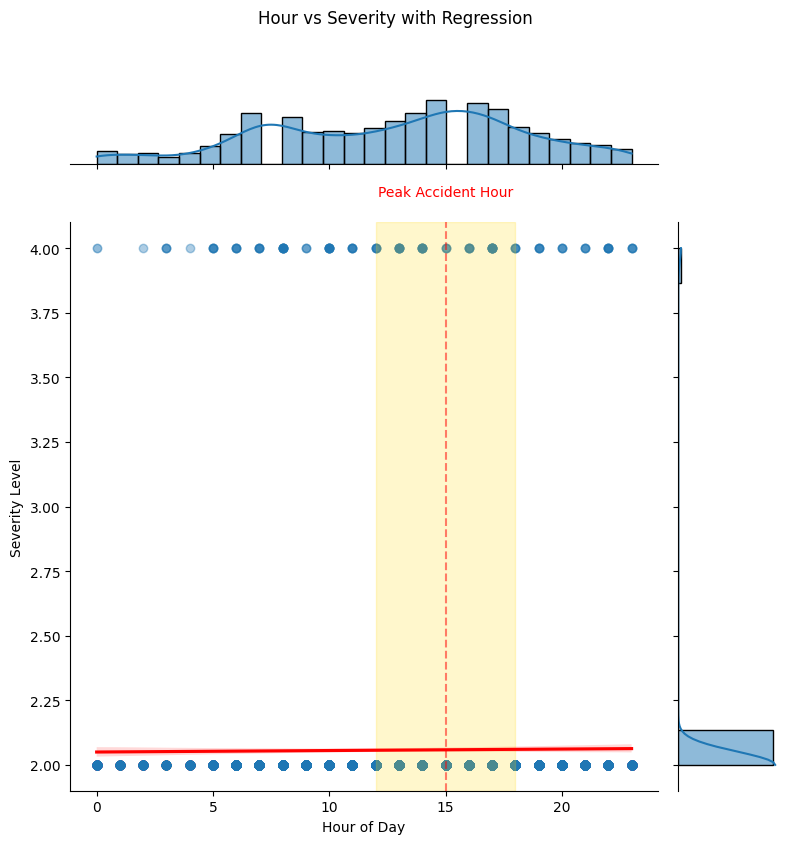

In [73]:
# joint plot
# More advanced joint plot with regression
g = sns.jointplot(data=df_sample, 
                 x='hour', 
                 y='Severity',
                 kind='reg',  # Adds regression line
                 scatter_kws={'alpha': 0.2},
                 line_kws={'color': 'red'},
                 height=8)

# Highlight peak period
g.ax_joint.axvspan(12, 18, color='gold', alpha=0.2)
g.ax_joint.axvline(x=15, color='red', linestyle='--', alpha=0.5)

# Add distribution insights
g.ax_joint.text(15, df_sample['Severity'].max()+0.2, 
               'Peak Accident Hour', 
               ha='center', color='red')

g.ax_joint.set_xlabel('Hour of Day')
g.ax_joint.set_ylabel('Severity Level')
g.fig.suptitle('Hour vs Severity with Regression', y=1.05)

plt.tight_layout()
plt.show()

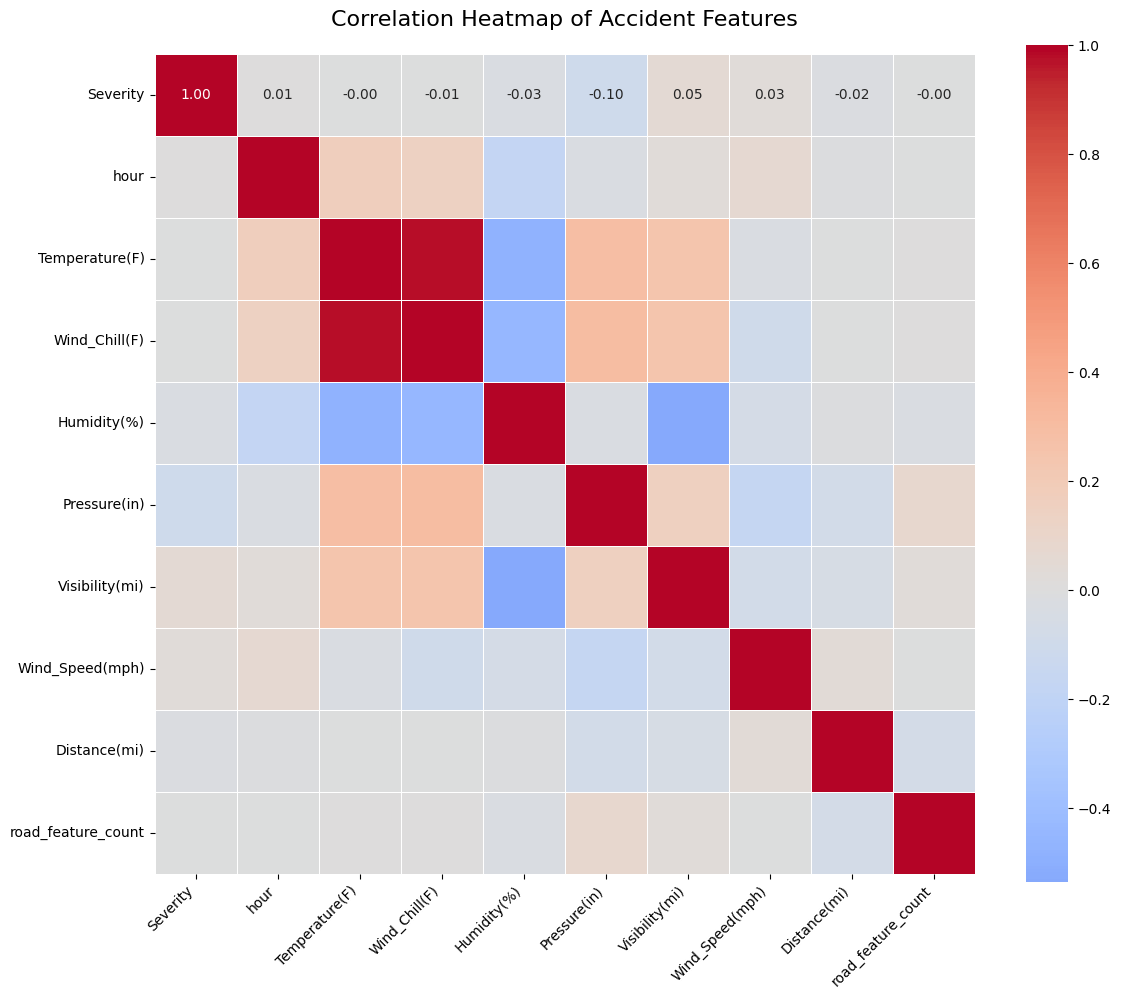

In [74]:
# correlation plot
# Define numerical features
numerical_features = [
    'Severity', 'hour', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)',
    'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Distance(mi)', 'road_feature_count'
]

# Keep only existing columns
numerical_features = [col for col in numerical_features if col in df_sample.columns]

# Show missing columns for debugging
missing_cols = set([
    'Severity', 'hour', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)',
    'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Distance(mi)', 'road_feature_count'
]) - set(df_sample.columns)
if missing_cols:
    print(f"Missing columns: {missing_cols}")

# Calculate correlation matrix safely
corr_matrix = df_sample[numerical_features].corr()

# Plot heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True, fmt=".2f", cmap='coolwarm', center=0,
    linewidths=0.5, linecolor='white', square=True
)
plt.title('Correlation Heatmap of Accident Features', pad=20, fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


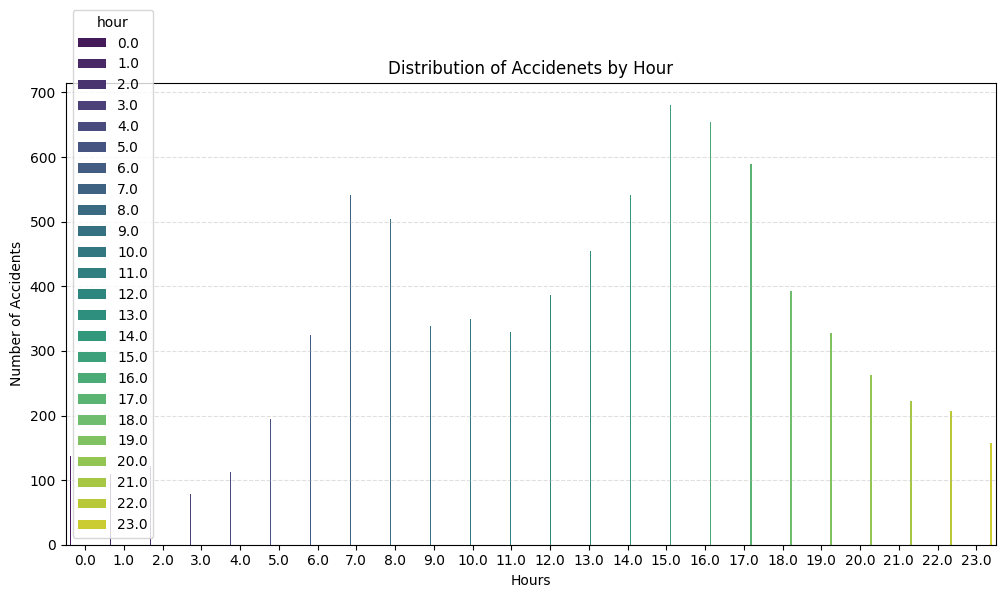

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns
df_sample['hour'] = df_sample['Start_Time'].dt.hour
plt.figure(figsize = (12 , 6))
sns.countplot(data = df_sample , x= "hour" , hue = "hour" , palette = 'viridis')
plt.title("Distribution of Accidenets by Hour")
plt.xlabel("Hours")
plt.ylabel("Number of Accidents")
plt.grid(axis = 'y' , linestyle = '--' , alpha =0.4)

C:\Users\DELL\AppData\Local\Temp\ipykernel_15396\2729861367.py:103: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  'timestamp': pd.date_range('2023-01-01', periods=1000, freq='H'),


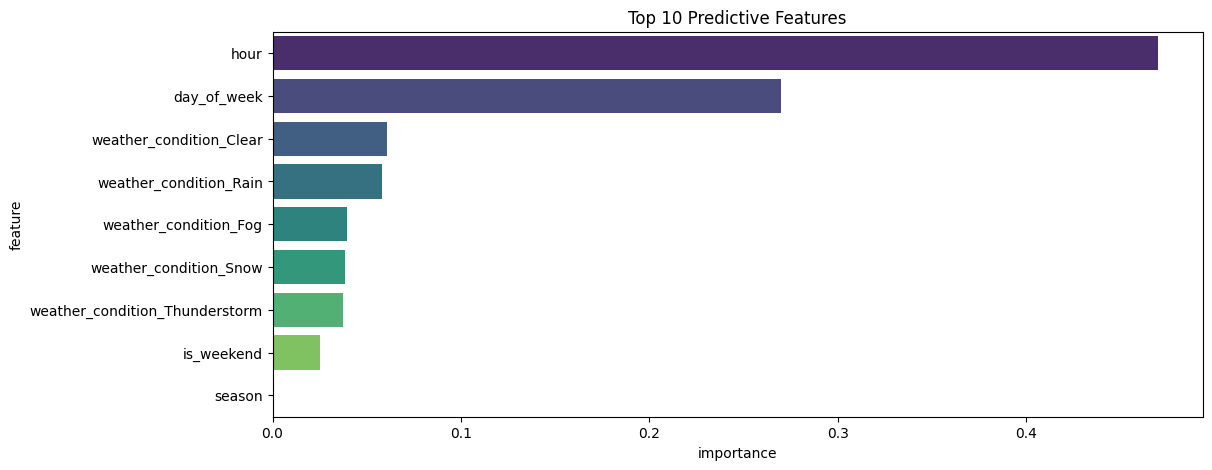

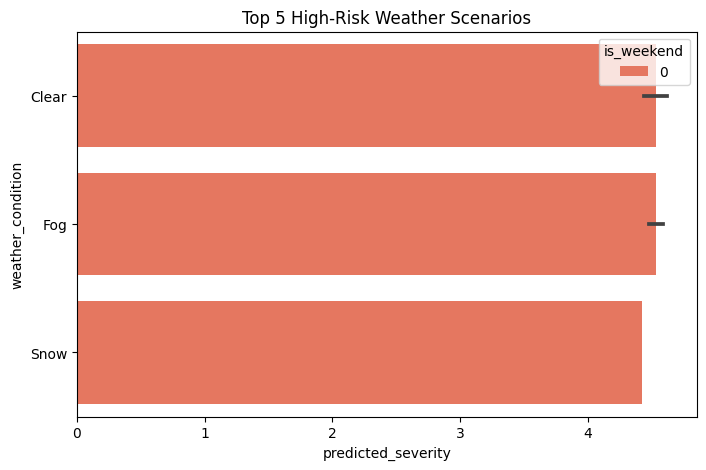

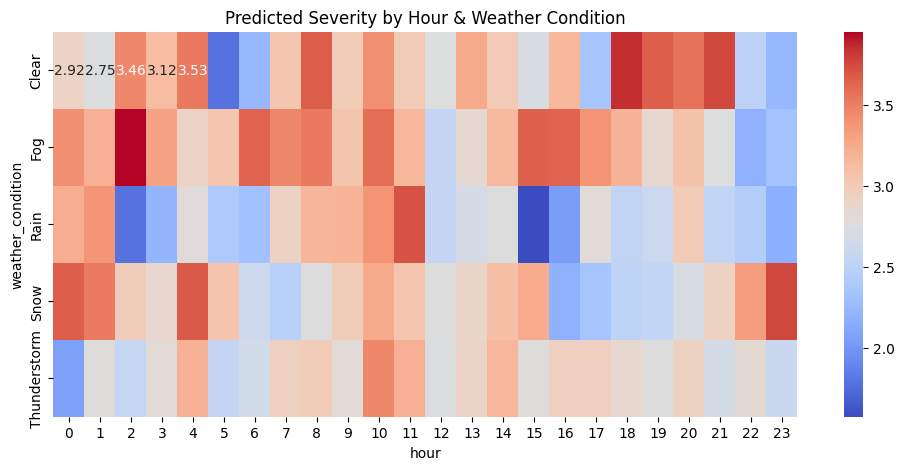


Model MAE: 1.20
TOP RISK SCENARIOS:

1. Clear | Weekday | Hour 18 | Severity: 4.62
   - Maintain normal monitoring
   - Coordinate with traffic department for detours
   - Activate emergency response teams

2. Fog | Weekday | Hour 10 | Severity: 4.59
   - Activate fog lights on highways
   - Lower speed limits
   - Coordinate with traffic department for detours
   - Activate emergency response teams

3. Fog | Weekday | Hour 6 | Severity: 4.48
   - Activate fog lights on highways
   - Lower speed limits
   - Coordinate with traffic department for detours
   - Activate emergency response teams

4. Clear | Weekday | Hour 20 | Severity: 4.44
   - Maintain normal monitoring
   - Coordinate with traffic department for detours
   - Activate emergency response teams

5. Snow | Weekday | Hour 4 | Severity: 4.42
   - Salt roads
   - Deploy snow plows
   - Coordinate with traffic department for detours
   - Activate emergency response teams



In [76]:
# analysis to predict the final decsion 
#summery and some recommendations  
import pandas as pd, numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt, seaborn as sns, joblib

# Build model
def build_model(df):
    df['day_of_week'] = df['timestamp'].dt.dayofweek
    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)
    df['season'] = df['timestamp'].dt.month % 12 // 3 + 1
    X = pd.get_dummies(df[['hour', 'day_of_week', 'is_weekend', 'season', 'weather_condition']])
    y = df['severity']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
    mae = mean_absolute_error(y_test, model.predict(X_test))
    importance = pd.DataFrame({'feature': X.columns, 'importance': model.feature_importances_}).sort_values('importance', ascending=False)
    return model, mae, importance

# Simulate scenarios
def simulate(model, weather_conditions):
    scenarios = [
        {'hour': h, 'weather_condition': w, 'is_weekend': we, 'day_of_week': 5 if we else 0, 'season': 2}
        for h in range(24) for w in weather_conditions for we in [0, 1]
    ]
    df = pd.DataFrame(scenarios)
    features = pd.get_dummies(df)
    for col in set(model.feature_names_in_) - set(features.columns):
        features[col] = 0
    df['predicted_severity'] = model.predict(features[model.feature_names_in_])
    return df

# Dynamic action generator
def dynamic_actions(weather, is_weekend, severity):
    actions = []
    # Weather-specific
    if weather == 'Rain':
        actions += ["Check drainage systems", "Deploy road safety signs"]
    elif weather == 'Snow':
        actions += ["Salt roads", "Deploy snow plows"]
    elif weather == 'Fog':
        actions += ["Activate fog lights on highways", "Lower speed limits"]
    elif weather == 'Thunderstorm':
        actions += ["Inspect power lines", "Close unsafe outdoor areas"]
    else:
        actions += ["Maintain normal monitoring"]
    # Weekend vs weekday
    if is_weekend:
        actions.append("Run public awareness messages on social media")
    else:
        actions.append("Coordinate with traffic department for detours")
    # Severity-based
    if severity >= 4:
        actions.append("Activate emergency response teams")
    elif severity >= 3:
        actions.append("Issue caution alerts to the public")
    return actions

# Generate recommendations
def recommendations(scenarios, mae):
    top5 = scenarios.sort_values('predicted_severity', ascending=False).head(5)
    report = f"Model MAE: {mae:.2f}\nTOP RISK SCENARIOS:\n"
    for i, r in enumerate(top5.itertuples(), 1):
        report += f"\n{i}. {r.weather_condition} | {'Weekend' if r.is_weekend else 'Weekday'} | Hour {r.hour} | Severity: {r.predicted_severity:.2f}\n"
        for action in dynamic_actions(r.weather_condition, r.is_weekend, r.predicted_severity):
            report += f"   - {action}\n"
    return report, top5

# Full analysis pipeline
def run(filepath):
    df = pd.read_csv(filepath)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df['hour'] = df['timestamp'].dt.hour
    df.dropna(subset=['severity', 'weather_condition'], inplace=True)

    model, mae, importance = build_model(df)
    scenarios = simulate(model, df['weather_condition'].unique())
    report, top5 = recommendations(scenarios, mae)

    # Feature importance plot
    plt.figure(figsize=(12, 5))
    sns.barplot(x='importance', y='feature', data=importance.head(10), palette='viridis')
    plt.title('Top 10 Predictive Features'); plt.show()

    # Top 5 scenarios plot
    plt.figure(figsize=(8, 5))
    sns.barplot(x='predicted_severity', y='weather_condition', hue='is_weekend', data=top5, palette='Reds')
    plt.title('Top 5 High-Risk Weather Scenarios'); plt.show()

    # Heatmap
    pivot_df = scenarios.pivot_table(values='predicted_severity', index='weather_condition', columns='hour', aggfunc='mean')
    plt.figure(figsize=(12, 5))
    sns.heatmap(pivot_df, annot=True, fmt=".2f", cmap='coolwarm')
    plt.title('Predicted Severity by Hour & Weather Condition'); plt.show()

    return {'model': model, 'scenarios': scenarios, 'report': report}

# Example run
if __name__ == "__main__":
    data = {
        'timestamp': pd.date_range('2023-01-01', periods=1000, freq='H'),
        'severity': np.clip(np.random.normal(3, 1.5, 1000), 1, 5).round(),
        'weather_condition': np.random.choice(['Clear', 'Rain', 'Snow', 'Fog', 'Thunderstorm'], 1000, p=[0.5, 0.2, 0.1, 0.1, 0.1])
    }
    pd.DataFrame(data).to_csv('weather_incidents.csv', index=False)

    results = run('weather_incidents.csv')
    print("\n" + results['report'])
    joblib.dump(results['model'], 'severity_predictor.joblib')
